## Loading in Census data for household heating source

In [4]:
import pandas as pd

#import requests to be able to pass in the census API key and access the data
import requests

# 1. define census API key and census endpoint for 2022 ACS 5-year tract data (2022 is most recent)
api_key = "f33094cc5c703bb7fc5d634e5469bbd5e3781c5d"
url = f"https://api.census.gov/data/2022/acs/acs5?get=NAME,B25040_001E,B25040_002E,B25040_004E&for=tract:*&in=state:06&key={api_key}"
response = requests.get(url)

# 2. check if the request was successful
if response.status_code == 200:
    data = response.json()
    
    #the first row contains the column headers, the rest are data rows
    headers = data[0]
    rows = data[1:]
    
    #convert into a Pandas DataFrame
    df_housing = pd.DataFrame(rows, columns=headers)
    
    #create the standard 11-digit GEOID (state + county + tract) --> need this in order to match with CDC health data later on
    df_housing['GEOID'] = df_housing['state'] + df_housing['county'] + df_housing['tract']
    
    #rename columns for readability
    df_housing = df_housing.rename(columns={
        'B25040_001E': 'total_units',
        'B25040_002E': 'utility_gas_units',
        'B25040_004E': 'electricity_units'
    })

    #quick print statement to display number of tracts
    print(f"Successfully downloaded housing data for {len(df_housing)} tracts!")
    display(df_housing.head())

#print error statement if above code doesn't work
else:
    print(f"Error fetching data: {response.status_code}")
    print(response.text)

Successfully downloaded housing data for 9129 tracts!


,NAME,total_units,utility_gas_units,electricity_units,state,county,tract,GEOID
0,Census Tract 4001; Alameda County; California,1377,1240,109,06,001,400100,06001400100
1,Census Tract 4002; Alameda County; California,876,676,157,06,001,400200,06001400200
2,Census Tract 4003; Alameda County; California,2638,1936,702,06,001,400300,06001400300
3,Census Tract 4004; Alameda County; California,1760,1324,341,06,001,400400,06001400400
4,Census Tract 4005; Alameda County; California,1679,1235,302,06,001,400500,06001400500


## Loading in CDC Places Asthma Data

In [7]:
# 1. get CDC PLACES asthma data for CA
places_url = "https://data.cdc.gov/resource/shc3-fzig.csv?stateabbr=CA&$limit=10000"

#convert into a dataframe
df_health = pd.read_csv(places_url)

#print out column names to inspect how they are capitalized
print("\nAvailable columns in health dataset:")
print(df_health.columns.tolist())

# 2. find correct FIPS column (handles both 'TractFIPS' and 'tractfips') --> need to standardize and fix capitalization discrepancies
fips_col = [col for col in df_health.columns if col.lower() == 'tractfips']

if fips_col:
    fips_column_name = fips_col[0]
    print(f"\nFound tract identifier column: '{fips_column_name}'")
    
    #standardize to 11-digit GEOID string --> need to match housing data in order to merge later on
    df_health['GEOID'] = df_health[fips_column_name].astype(str).str.zfill(11)
    
    #identify asthma prevalence column 
    asthma_col = [col for col in df_health.columns if 'casthma' in col.lower() and 'crudeprev' in col.lower()]
    target_asthma = asthma_col[0] if asthma_col else 'CASTHMA_CrudePrev'
    print(f"Using asthma prevalence column: '{target_asthma}'")
    
    #keep essential columns
    cols_to_keep = ['GEOID', target_asthma]
    if 'TotalPopulation' in df_health.columns:
        cols_to_keep.append('TotalPopulation')
        
    df_health_clean = df_health[cols_to_keep].copy()
    if target_asthma != 'CASTHMA_CrudePrev':
        df_health_clean = df_health_clean.rename(columns={target_asthma: 'CASTHMA_CrudePrev'})
else:
    print("\nError: Could not locate a tract FIPS column. Please check the printed column list above.")


Available columns in health dataset:
['stateabbr', 'statedesc', 'countyname', 'countyfips', 'tractfips', 'totalpopulation', 'access2_crudeprev', 'access2_crude95ci', 'arthritis_crudeprev', 'arthritis_crude95ci', 'binge_crudeprev', 'binge_crude95ci', 'bphigh_crudeprev', 'bphigh_crude95ci', 'bpmed_crudeprev', 'bpmed_crude95ci', 'cancer_crudeprev', 'cancer_crude95ci', 'casthma_crudeprev', 'casthma_crude95ci', 'cervical_crudeprev', 'cervical_crude95ci', 'chd_crudeprev', 'chd_crude95ci', 'checkup_crudeprev', 'checkup_crude95ci', 'cholscreen_crudeprev', 'cholscreen_crude95ci', 'colon_screen_crudeprev', 'colon_screen_crude95ci', 'copd_crudeprev', 'copd_crude95ci', 'corem_crudeprev', 'corem_crude95ci', 'corew_crudeprev', 'corew_crude95ci', 'csmoking_crudeprev', 'csmoking_crude95ci', 'dental_crudeprev', 'dental_crude95ci', 'depression_crudeprev', 'depression_crude95ci', 'diabetes_crudeprev', 'diabetes_crude95ci', 'ghlth_crudeprev', 'ghlth_crude95ci', 'highchol_crudeprev', 'highchol_crude95ci',

## Merge datasets together into one dataframe

In [8]:
#merge housing data and asthma prevalence data

merged_df = pd.merge(df_housing, df_health_clean, on='GEOID', how='inner')

display(merged_df.head())
    
#save as csv as well
merged_df.to_csv("ca_heating_vs_asthma_tracts.csv", index=False)

,NAME,total_units,utility_gas_units,electricity_units,state,county,tract,GEOID,CASTHMA_CrudePrev
0,Census Tract 4001; Alameda County; California,1377,1240,109,06,001,400100,06001400100,8.2
1,Census Tract 4002; Alameda County; California,876,676,157,06,001,400200,06001400200,8.5
2,Census Tract 4003; Alameda County; California,2638,1936,702,06,001,400300,06001400300,9.3
3,Census Tract 4004; Alameda County; California,1760,1324,341,06,001,400400,06001400400,9.5
4,Census Tract 4005; Alameda County; California,1679,1235,302,06,001,400500,06001400500,9.9


## Summary of work so far

### Overview 
So far, we have loaded in two main datasets: the ACS Table B25040 House Heating Fuel dataset from the official U.S. Census Bureau website and the CDC PLACES Asthma Data dataset from the CDC PLACES Data Portal. The links to these two portals are: 

* https://data.census.gov
* https://www.cdc.gov/places/index.html

### Quick breakdown

#### ACS Table B25040 House Heating Fuel Dataset

This dataset provides survey data collected at the neighborhood level detailing physical characteristics of residential homes. 

It gives us the counts of housing units for different primary heating fuel types, like utility gas versus electric. 

This data is important for this research becasue it serves as our independent variable. We want to see if having gas heating vs electric or some other source has any impacts on health outcomes. So this data will allow us to calculate what percentage of homes in a given neighborhood rely on gas vs. electric. We can then compare those percentages with asthma prevalance in different neighborhoods and see if there is any correlation (once we control for other variables/confounders)

#### CDC PLACES Dataset

This dataset is a model-based public health estimate dataset published by the CDC. The data is derived from Behavioral Risk Factor Surveillance System data, Census population data, and American Community Survey data. They use a small area estimate (SAE) approach, combining multilevel regression and poststratification to get estimates for each census tract. Methodology source: https://www.cdc.gov/places/methodology/index.html 

It gives us modeled neighborhood-level prevalence rates for specific medical conditions, including adult asthma rates. 
This data is important for this research because it is our independent variable. We want to see how common asthma is within specific neighborhoods and see if there is any correlation between asthma prevalence and heating type. 

#### 11-Digit Census Tract GEOID

The U.S. Census Bureau assigns a unique numeric code to every neighborhood area. We use these GEOIDs to match the data from the housing dataset with the data from the asthma prevalence dataset so that we can merge the datasets and accurately overlay the datasets to see both for the exact same neighborhoods.

## Initial graphical analysis

--- Statistical Summary ---
Pearson Correlation Coefficient (r): -0.248
P-value: 4.4877e-96



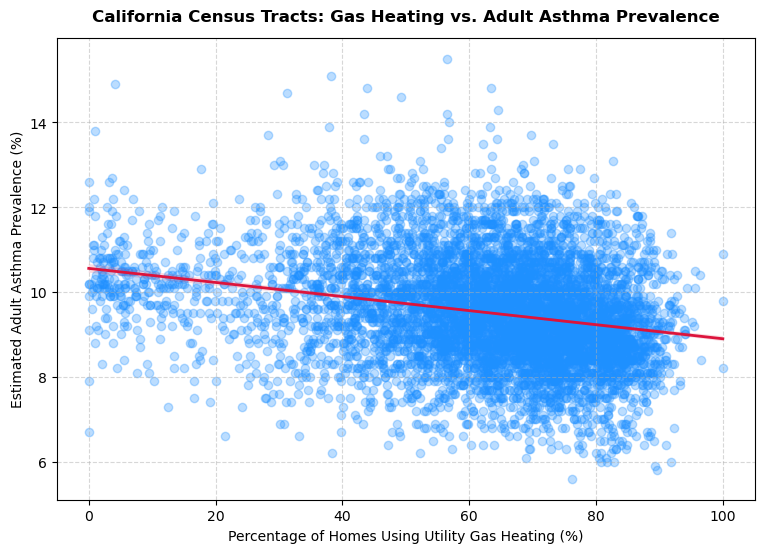

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# 1. Load your saved merged dataset
df = pd.read_csv("ca_heating_vs_asthma_tracts.csv")

# Ensure numeric types for calculations
df['total_units'] = pd.to_numeric(df['total_units'], errors='coerce')
df['utility_gas_units'] = pd.to_numeric(df['utility_gas_units'], errors='coerce')
df['CASTHMA_CrudePrev'] = pd.to_numeric(df['CASTHMA_CrudePrev'], errors='coerce')

# Drop rows with missing values or zero total units to prevent errors
df = df.dropna(subset=['total_units', 'utility_gas_units', 'CASTHMA_CrudePrev'])
df = df[df['total_units'] > 0]

# 2. Calculate the percentage of homes using utility gas per tract
df['pct_utility_gas'] = (df['utility_gas_units'] / df['total_units']) * 100

# 3. Calculate Pearson correlation coefficient and p-value
corr, p_value = pearsonr(df['pct_utility_gas'], df['CASTHMA_CrudePrev'])
print(f"--- Statistical Summary ---")
print(f"Pearson Correlation Coefficient (r): {corr:.3f}")
print(f"P-value: {p_value:.4e}\n")

# 4. Create a scatter plot with a regression trendline
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df, 
    x='pct_utility_gas', 
    y='CASTHMA_CrudePrev',
    scatter_kws={'alpha': 0.3, 'color': 'dodgerblue'}, # semi-transparent points to show density
    line_kws={'color': 'crimson', 'linewidth': 2}      # trend line
)

plt.title('California Census Tracts: Gas Heating vs. Adult Asthma Prevalence', fontsize=12, pad=12, fontweight='bold')
plt.xlabel('Percentage of Homes Using Utility Gas Heating (%)', fontsize=10)
plt.ylabel('Estimated Adult Asthma Prevalence (%)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()